# How to Explore Synthetic Healthcare Data with Python

**A hands-on companion notebook for the freeCodeCamp tutorial: _How to Generate Synthetic Healthcare Data Using Synthea_.**

Synthea generates simulated patient histories. This notebook helps you explore what those records contain, how the CSV files relate, and how to follow one patient across encounters, conditions, observations, medications, and procedures.

### What you'll learn

1. Load and inspect six Synthea CSV datasets with Pandas.
2. Understand healthcare terms: **patient**, **encounter**, **condition**, **observation**, **medication**, and **procedure**.
3. Explore distributions, clinical codes, numeric vs. text observations, and missing values.
4. Reconstruct an example patient's longitudinal timeline.
5. Check basic data integrity without treating every missing value as an error.

> **Important:** Synthea records are fictional. They are useful for education and testing but should not be assumed to reproduce real-world clinical distributions. No actual patient data is needed for this notebook.

## 0. Setup: generate the Synthea CSV files

Install and run [Synthea](https://github.com/synthetichealth/synthea) as explained in the accompanying article. From the Synthea repository root:

```bash
./run_synthea -s 12345 -p 100 --exporter.csv.export=true
```

**The `-p 100` setting is a population target, not necessarily exactly 100 exported records:** population overflow and other simulation settings can affect the count.

Your files should be in:

```text
synthea/
├── output/
│   └── csv/
│       ├── patients.csv
│       ├── encounters.csv
│       ├── conditions.csv
│       ├── observations.csv
│       ├── medications.csv
│       └── procedures.csv
└── explore_synthea_healthcare_data.ipynb  ← you can put this notebook here
```

Install the Python packages into your environment if needed:

```bash
python3 -m pip install jupyter pandas numpy matplotlib
jupyter notebook
```

**Path tip:** Open this notebook from the `synthea` folder, or change `CSV_DIR_OVERRIDE` in the next code cell to the absolute location of your `output/csv` folder. The notebook also checks a few common nearby locations.

For a clean, reproducible dataset, use a known Synthea revision and clear/rotate previously generated exports before regenerating (after backing up anything you want to keep).

## 1. Imports and locate the CSV directory

We'll keep identifiers as **strings**, since IDs and clinical codes are labels, not numbers. Some codes may start with zeros.

The next cell stops with a helpful error if the dataset isn't present, rather than silently generating made-up patient records.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)

# Optional: set this to a full path, for example "/Users/you/synthea/output/csv".
CSV_DIR_OVERRIDE = None

required_names = [
    "patients", "encounters", "conditions",
    "observations", "medications", "procedures"
]

candidates = []
if CSV_DIR_OVERRIDE:
    candidates.append(Path(CSV_DIR_OVERRIDE).expanduser())
if os.environ.get("SYNTHEA_CSV_DIR"):
    candidates.append(Path(os.environ["SYNTHEA_CSV_DIR"]).expanduser())

candidates += [
    Path("output/csv"),
    Path("../output/csv"),
    Path("synthea/output/csv"),
    Path("../synthea/output/csv"),
    Path.home() / "synthea/output/csv",
]

csv_dir = next(
    (
        path.resolve() for path in candidates
        if all((path / f"{name}.csv").is_file() for name in required_names)
    ),
    None,
)

if csv_dir is None:
    raise FileNotFoundError(
        "Could not find all six Synthea CSV files. "
        "Set CSV_DIR_OVERRIDE to the folder containing patients.csv, "
        "encounters.csv, conditions.csv, observations.csv, "
        "medications.csv, and procedures.csv."
    )

print("Reading Synthea CSV files from:", csv_dir)

Reading Synthea CSV files from: /Users/lakshmi/synthea/output/csv


## 2. Load the datasets

The six files describe related clinical entities. Most contain a `PATIENT` column pointing to the `Id` field in `patients.csv`; event records can also reference an encounter through `ENCOUNTER`.

We read identifier and code fields as text and parse dates explicitly later. In particular, `observations.VALUE` can contain either numeric measurements **or** categorical values.

In [2]:
text_columns = {
    "Id": "string", "PATIENT": "string", "ENCOUNTER": "string",
    "CODE": "string", "SYSTEM": "string", "VALUE": "string",
    "ZIP": "string", "FIPS": "string"
}

tables = {
    name: pd.read_csv(
        csv_dir / f"{name}.csv", dtype=text_columns, low_memory=False
    )
    for name in required_names
}

patients = tables["patients"]
encounters = tables["encounters"]
conditions = tables["conditions"]
observations = tables["observations"]
medications = tables["medications"]
procedures = tables["procedures"]

summary = pd.DataFrame([
    {"dataset": name, "rows": len(df), "columns": len(df.columns),
     "unique_patients": df["Id"].nunique() if name == "patients"
                        else df["PATIENT"].nunique()}
    for name, df in tables.items()
])
display(summary)

,dataset,rows,columns,unique_patients
0,patients,115,28,115
1,encounters,5985,15,115
2,conditions,4070,7,115
3,observations,75004,9,115
4,medications,4454,13,111
5,procedures,16777,10,114


### Healthcare terminology at a glance

| Table | What one row usually represents | Key relationship |
|---|---|---|
| `patients` | A simulated person's demographic record | `Id` identifies the patient |
| `encounters` | A healthcare visit or interaction | `PATIENT` → patient `Id` |
| `conditions` | A diagnosis, condition, or finding | `PATIENT`; usually `ENCOUNTER` |
| `observations` | A lab result, vital sign, or other observation | `PATIENT`; sometimes `ENCOUNTER` |
| `medications` | A medication record | `PATIENT`; often `ENCOUNTER` |
| `procedures` | A recorded clinical procedure | `PATIENT`; often `ENCOUNTER` |

**Important nuance:** `conditions` can contain findings beyond diagnoses, and `observations` can contain numeric *or* textual values. Clinical code systems and units add meaning beyond plain descriptions.

In [3]:
# Preview only fields relevant to the teaching example.
# The source dataset also contains invented names, SSNs, and addresses;
# we intentionally avoid displaying those fields.
patient_columns = [
    c for c in ["Id", "BIRTHDATE", "DEATHDATE", "GENDER", "RACE", "CITY", "STATE"]
    if c in patients.columns
]
display(patients[patient_columns].head(5))

print("Encounter columns:", encounters.columns.tolist())
print("Observation columns:", observations.columns.tolist())

,Id,BIRTHDATE,DEATHDATE,GENDER,RACE,CITY,STATE
0,a35dfdc9-1d97-63e0-a0b6-3e97b6fd5fe1,1995-11-05,NaN,M,white,Boston,Massachusetts
1,72b5373b-e9f1-db2d-6c43-4506fb4b3e3f,1962-05-02,1974-11-22,F,white,Lynn,Massachusetts
2,f1f05592-2511-92df-6f3e-c64ac3152b26,1983-07-07,NaN,F,white,Middleborough,Massachusetts
3,7a58a941-bd27-086e-d622-38e5917d0df5,1957-04-25,NaN,F,white,Colrain,Massachusetts
4,c4d5d909-433c-fccf-5984-4213b88417cb,1978-07-13,NaN,M,black,Whitman,Massachusetts


Encounter columns: ['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PROVIDER', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION']
Observation columns: ['DATE', 'PATIENT', 'ENCOUNTER', 'CATEGORY', 'CODE', 'DESCRIPTION', 'VALUE', 'UNITS', 'TYPE']


## 3. Explore encounters — the backbone of the patient journey

An **encounter** is a contact with the healthcare system, such as an outpatient appointment, emergency department visit, or inpatient stay.

Different patients can have very different numbers of encounters. Use counts to discover the simulated population's patterns, not to draw clinical conclusions about actual populations.

,encounter_class,count
0,ambulatory,3134
1,wellness,1470
2,outpatient,826
3,urgentcare,215
4,emergency,164
5,inpatient,79
6,home,67
7,hospice,11
8,snf,11
9,virtual,8


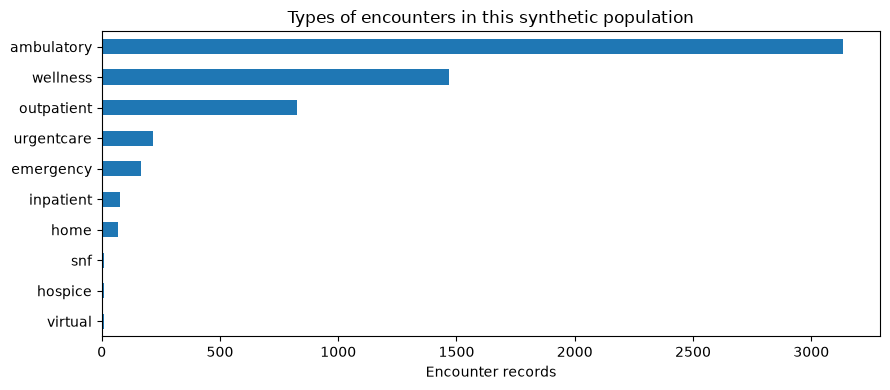

In [4]:
encounter_classes = (
    encounters["ENCOUNTERCLASS"]
    .fillna("Unknown")
    .value_counts()
)
display(encounter_classes.rename_axis("encounter_class").reset_index(name="count"))

fig, ax = plt.subplots(figsize=(9, 4))
encounter_classes.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Types of encounters in this synthetic population")
ax.set_xlabel("Encounter records")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Encounters per patient (including patients with zero encounters):


,count
count,115.000000
mean,52.043478
std,70.477244
min,4.000000
25%,26.500000
50%,39.000000
75%,60.500000
max,722.000000


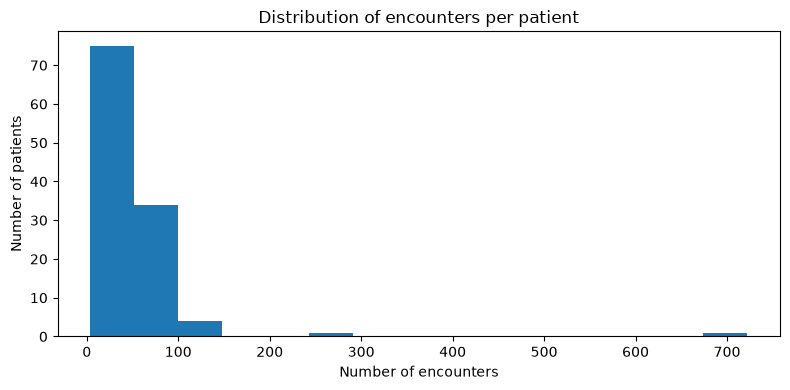

In [5]:
encounters_per_patient = (
    encounters.groupby("PATIENT").size()
    .reindex(patients["Id"], fill_value=0)
)

print("Encounters per patient (including patients with zero encounters):")
display(encounters_per_patient.describe().to_frame(name="count"))

fig, ax = plt.subplots(figsize=(8, 4))
encounters_per_patient.plot(kind="hist", bins=15, ax=ax)
ax.set_title("Distribution of encounters per patient")
ax.set_xlabel("Number of encounters")
ax.set_ylabel("Number of patients")
plt.tight_layout()
plt.show()

## 4. Conditions and coding systems

The `conditions` table includes a `SYSTEM`, `CODE`, and `DESCRIPTION`. A human-readable description can be convenient for teaching, but downstream systems should also understand the code and its terminology system.

A condition entry isn't necessarily a disease diagnosis: depending on the source module, it may represent a clinical or social-history finding.

In [6]:
display(
    conditions[["SYSTEM", "CODE", "DESCRIPTION"]]
    .head(10)
)

print("Most frequent condition/finding descriptions:")
display(
    conditions["DESCRIPTION"]
    .fillna("Unknown")
    .value_counts()
    .head(12)
    .rename_axis("description")
    .reset_index(name="count")
)

,SYSTEM,CODE,DESCRIPTION
0,SNOMED-CT,224299000,Received higher education (finding)
1,SNOMED-CT,713458007,Lack of access to transportation (finding)
2,SNOMED-CT,82423001,Chronic pain (finding)
3,SNOMED-CT,278860009,Chronic low back pain (finding)
4,SNOMED-CT,1121000119107,Chronic neck pain (finding)
5,SNOMED-CT,266934004,Transport problem (finding)
6,SNOMED-CT,160903007,Full-time employment (finding)
7,SNOMED-CT,314529007,Medication review due (situation)
8,SNOMED-CT,109570002,Primary dental caries (disorder)
9,SNOMED-CT,741062008,Not in labor force (finding)


Most frequent condition/finding descriptions:


,description,count
0,Medication review due (situation),758
1,Stress (finding),307
2,Gingivitis (disorder),305
3,Full-time employment (finding),287
4,Part-time employment (finding),175
5,Viral sinusitis (disorder),128
6,Social isolation (finding),124
7,Limited social contact (finding),120
8,Not in labor force (finding),93
9,Gingival disease (disorder),87


## 5. Observations — numeric measurements and categorical results

`observations.csv` is often the biggest file. An observation can be a vital sign, a lab result, a text response, or another coded measurement.

**Never treat every `VALUE` as a number.** And don't compare numbers without checking `UNITS`, clinical code, and context.

In [7]:
obs_preview_cols = [
    c for c in ["DATE", "CATEGORY", "CODE", "DESCRIPTION", "VALUE", "UNITS", "TYPE"]
    if c in observations.columns
]
display(observations[obs_preview_cols].head(10))

print("Most common observation descriptions:")
display(
    observations["DESCRIPTION"]
    .fillna("Unknown")
    .value_counts()
    .head(12)
    .rename_axis("description")
    .reset_index(name="count")
)

,DATE,CATEGORY,CODE,DESCRIPTION,VALUE,UNITS,TYPE
0,2018-01-07T16:36:29Z,vital-signs,8302-2,Body Height,182.6,cm,numeric
1,2018-01-07T16:36:29Z,vital-signs,72514-3,Pain severity - 0-10 verbal numeric rating [Score] - Reported,3.0,{score},numeric
2,2018-01-07T16:36:29Z,vital-signs,29463-7,Body Weight,83.6,kg,numeric
3,2018-01-07T16:36:29Z,vital-signs,39156-5,Body mass index (BMI) [Ratio],25.1,kg/m2,numeric
4,2018-01-07T16:36:29Z,vital-signs,8462-4,Diastolic Blood Pressure,68.0,mm[Hg],numeric
5,2018-01-07T16:36:29Z,vital-signs,8480-6,Systolic Blood Pressure,130.0,mm[Hg],numeric
6,2018-01-07T16:36:29Z,vital-signs,8867-4,Heart rate,83.0,/min,numeric
7,2018-01-07T16:36:29Z,vital-signs,9279-1,Respiratory rate,15.0,/min,numeric
8,2018-01-07T16:36:29Z,laboratory,6690-2,Leukocytes [#/volume] in Blood by Automated count,8.6,10*3/uL,numeric
9,2018-01-07T16:36:29Z,laboratory,789-8,Erythrocytes [#/volume] in Blood by Automated count,5.3,10*6/uL,numeric


Most common observation descriptions:


,description,count
0,Pain severity - 0-10 verbal numeric rating [Score] - Reported,1963
1,Diastolic Blood Pressure,1456
2,Systolic Blood Pressure,1456
3,Body Weight,1440
4,Heart rate,1425
5,Respiratory rate,1425
6,Body Height,1402
7,Tobacco smoking status,1402
8,Body mass index (BMI) [Ratio],1319
9,Within the last year have you been afraid of your partner or ex-partner,1092


In [8]:
# A numeric parse is useful for *exploration* but should not overwrite the original.
# Many nonnumeric values are expected to be categorical and are not errors.
observations_explored = observations.copy()
observations_explored["numeric_value"] = pd.to_numeric(
    observations_explored["VALUE"], errors="coerce"
)

nonmissing_count = observations_explored["VALUE"].notna().sum()
numeric_count = observations_explored["numeric_value"].notna().sum()
print(f"Observation rows with values: {nonmissing_count:,}")
print(f"Rows whose values can be parsed as numeric: {numeric_count:,}")
print(f"Among nonmissing values, numeric-like share: {numeric_count / max(nonmissing_count, 1):.1%}")

# Descriptions associated with multiple units deserve investigation, not automatic conversion.
if "UNITS" in observations.columns:
    units_per_description = (
        observations.dropna(subset=["UNITS"])
        .groupby("DESCRIPTION")["UNITS"]
        .nunique()
        .sort_values(ascending=False)
    )
    print("Observation descriptions with more than one recorded unit:")
    display(units_per_description[units_per_description > 1].head(10).to_frame("unit_count"))

Observation rows with values: 75,004
Rows whose values can be parsed as numeric: 46,480
Among nonmissing values, numeric-like share: 62.0%
Observation descriptions with more than one recorded unit:


,unit_count
DESCRIPTION,
Hemoglobin [Presence] in Urine by Test strip,2
Protein [Presence] in Urine by Test strip,2
Specific gravity of Urine by Test strip,2
Nitrite [Presence] in Urine by Test strip,2
Glucose [Presence] in Urine by Test strip,2
Troponin I.cardiac [Mass/volume] in Serum or Plasma by High sensitivity method,2
Glomerular filtration rate [Volume Rate/Area] in Serum or Plasma by Creatinine-based formula (MDRD)/1.73 sq M,2
Bilirubin.total [Presence] in Urine by Test strip,2
Ketones [Presence] in Urine by Test strip,2


## 6. Find a patient with a longitudinal record

Rather than assuming a particular patient ID exists, we select a patient who has encounters, conditions, and observations in **this run**. The selected patient varies with the simulation settings.

A patient having more recorded events doesn't necessarily imply worse health or higher clinical risk.

In [9]:
event_counts = pd.DataFrame(index=pd.Index(patients["Id"], name="patient_id"))
for name in ["encounters", "conditions", "observations", "medications", "procedures"]:
    event_counts[name] = (
        tables[name].groupby("PATIENT").size()
        .reindex(event_counts.index, fill_value=0)
    )

event_counts["event_total"] = event_counts.sum(axis=1)
with_history = event_counts[
    (event_counts["encounters"] > 0)
    & (event_counts["conditions"] > 0)
    & (event_counts["observations"] > 0)
]

patient_id = (
    with_history["event_total"].idxmax()
    if not with_history.empty
    else event_counts["event_total"].idxmax()
)

print("Selected synthetic patient ID:", patient_id)
display(event_counts.loc[[patient_id]])
display(patients.loc[patients["Id"] == patient_id, patient_columns])

Selected synthetic patient ID: 4502d801-eb39-5973-dbd8-364a8633e1a4


,encounters,conditions,observations,medications,procedures,event_total
patient_id,,,,,,
4502d801-eb39-5973-dbd8-364a8633e1a4,257,249,10219,806,1161,12692


,Id,BIRTHDATE,DEATHDATE,GENDER,RACE,CITY,STATE
113,4502d801-eb39-5973-dbd8-364a8633e1a4,1955-01-15,NaN,F,asian,Everett,Massachusetts


## 7. Trace a patient's clinical history across tables

Each table stores a different event type. We'll build one timeline with the first-level event description and date. This is **not** a clinical summary: it is a data-engineering demonstration of how different tables can be assembled into a longitudinal view.

In [10]:
timeline_parts = [
    ("encounters", "START", "Encounter"),
    ("conditions", "START", "Condition / finding"),
    ("observations", "DATE", "Observation"),
    ("medications", "START", "Medication"),
    ("procedures", "START", "Procedure"),
]

parts = []
for table_name, date_col, event_type in timeline_parts:
    df = tables[table_name]
    if date_col not in df.columns:
        print(f"Skipped {table_name}: date column {date_col!r} not found")
        continue
    subset = df.loc[df["PATIENT"] == patient_id].copy()
    if subset.empty:
        continue
    subset["event_date"] = pd.to_datetime(subset[date_col], errors="coerce", utc=True)
    subset["event_type"] = event_type
    subset["description"] = (
        subset["DESCRIPTION"].fillna("(no description)")
        if "DESCRIPTION" in subset.columns
        else "(no description)"
    )
    parts.append(subset[["event_date", "event_type", "description"]])

if not parts:
    raise ValueError("Selected patient has no dated events in the six CSV files")

timeline = (
    pd.concat(parts, ignore_index=True)
    .dropna(subset=["event_date"])
    .sort_values("event_date")
    .reset_index(drop=True)
)

print(f"Timeline contains {len(timeline):,} dated events")
display(timeline.head(15))
print("Most recent events:")
display(timeline.tail(15))

Timeline contains 12,692 dated events


,event_date,event_type,description
0,1973-03-10 00:00:00+00:00,Condition / finding,Received higher education (finding)
1,1973-03-10 17:15:53+00:00,Encounter,General examination of patient (procedure)
2,1983-03-26 00:00:00+00:00,Condition / finding,Prediabetes (finding)
3,1983-03-26 00:00:00+00:00,Condition / finding,Anemia (disorder)
4,1983-03-26 17:15:53+00:00,Encounter,General examination of patient (procedure)
5,1997-01-25 00:00:00+00:00,Condition / finding,Diabetes mellitus type 2 (disorder)
6,1997-01-25 17:15:53+00:00,Encounter,General examination of patient (procedure)
7,1999-01-30 00:00:00+00:00,Condition / finding,Metabolic syndrome X (disorder)
8,1999-01-30 00:00:00+00:00,Condition / finding,Hypertriglyceridemia (disorder)
9,1999-01-30 00:00:00+00:00,Condition / finding,Body mass index 30+ - obesity (finding)


Most recent events:


,event_date,event_type,description
12677,2026-10-24 17:15:53+00:00,Observation,Clarity of Urine
12678,2026-10-24 17:15:53+00:00,Observation,Color of Urine
12679,2026-10-24 17:15:53+00:00,Observation,Glucose [Mass/volume] in Urine by Test strip
12680,2026-10-24 17:15:53+00:00,Observation,Glucose [Presence] in Urine by Test strip
12681,2026-10-24 17:15:53+00:00,Observation,Bilirubin.total [Mass/volume] in Urine by Test strip
12682,2026-10-24 17:15:53+00:00,Observation,Bilirubin.total [Presence] in Urine by Test strip
12683,2026-10-24 17:15:53+00:00,Observation,Ketones [Mass/volume] in Urine by Test strip
12684,2026-10-24 17:15:53+00:00,Observation,Ketones [Presence] in Urine by Test strip
12685,2026-10-24 17:15:53+00:00,Observation,Specific gravity of Urine by Test strip
12686,2026-10-24 17:15:53+00:00,Observation,pH of Urine by Test strip


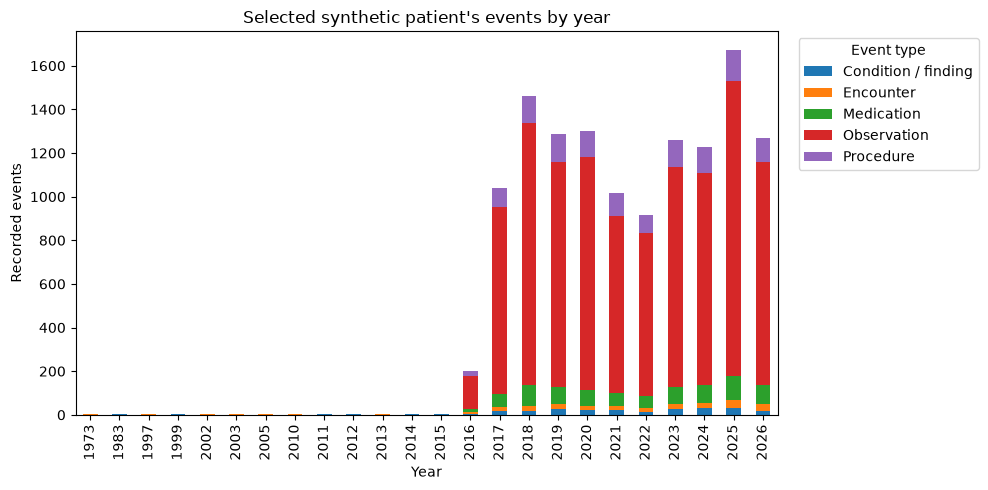

In [11]:
# Yearly event counts make the history easier to visualize.
timeline_plot = timeline.copy()
timeline_plot["year"] = timeline_plot["event_date"].dt.year
annual_events = (
    timeline_plot.groupby(["year", "event_type"]).size()
    .unstack(fill_value=0)
)

if not annual_events.empty:
    fig, ax = plt.subplots(figsize=(10, 5))
    annual_events.plot(kind="bar", stacked=True, ax=ax)
    ax.set_title("Selected synthetic patient's events by year")
    ax.set_xlabel("Year")
    ax.set_ylabel("Recorded events")
    ax.legend(title="Event type", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    print("No dated events were available for visualization.")

### Follow one observation over time

If the selected patient has repeated numeric measurements of a single `CODE` in a consistent unit, we can plot them. We don't hard-code HbA1c or glucose because the data generated by your Synthea run might not contain those observations.

**Warning:** numeric values with different units cannot be compared directly; this example keeps only one code-and-unit group.

Plotting: Glomerular filtration rate [Volume Rate/Area] in Serum or Plasma by Creatinine-based formula (MDRD)/1.73 sq M | code=33914-3 | unit=mL/min/{1.73_m2}


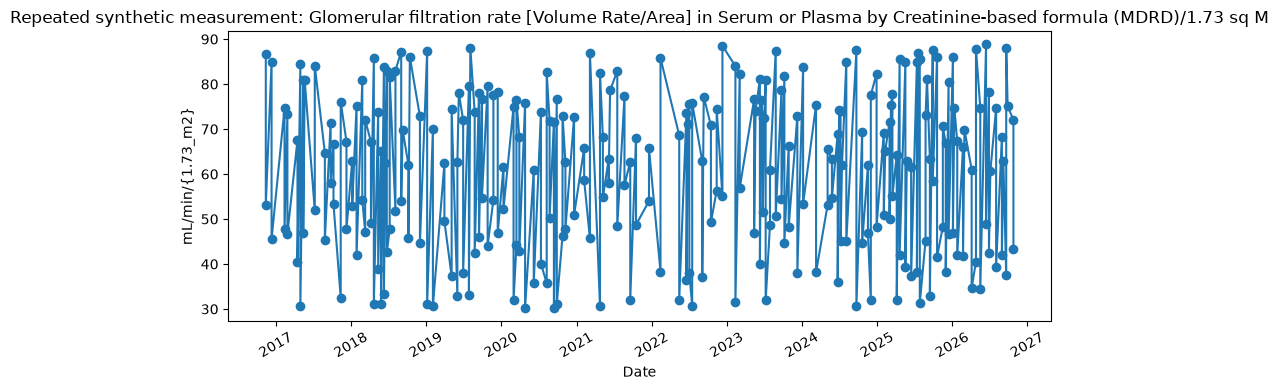

In [12]:
person_obs = observations_explored.loc[
    observations_explored["PATIENT"] == patient_id
].copy()
person_obs["event_date"] = pd.to_datetime(person_obs["DATE"], utc=True, errors="coerce")

numeric_series = person_obs.dropna(subset=["numeric_value", "event_date", "CODE"]).copy()
numeric_series["unit_label"] = numeric_series["UNITS"].fillna("(unit not provided)")
series_sizes = (
    numeric_series.groupby(["CODE", "unit_label"], dropna=False)
    .size()
    .sort_values(ascending=False)
)

if not series_sizes.empty and series_sizes.iloc[0] >= 2:
    selected_code, selected_unit = series_sizes.index[0]
    series_data = numeric_series.loc[
        (numeric_series["CODE"] == selected_code)
        & (numeric_series["unit_label"] == selected_unit)
    ].sort_values("event_date")
    description = str(series_data["DESCRIPTION"].iloc[0])
    print(f"Plotting: {description} | code={selected_code} | unit={selected_unit}")
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(series_data["event_date"], series_data["numeric_value"], marker="o")
    ax.set_title(f"Repeated synthetic measurement: {description}")
    ax.set_xlabel("Date")
    ax.set_ylabel(selected_unit)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("No repeated numeric observation was found for this patient.")

## 8. Basic dataset quality and relationship checks

Generated data should still be validated. We'll check unique patient IDs, references to patients, and links from events to encounters.

A missing encounter reference **is not automatically an error** (some Synthea observation types can legitimately lack an encounter). Our check flags **non-empty IDs that cannot be found**.

In [13]:
print("Duplicate patient IDs:", patients["Id"].duplicated().sum())
print("Duplicate encounter IDs:", encounters["Id"].duplicated().sum())

known_patient_ids = set(patients["Id"].dropna())
known_encounter_ids = set(encounters["Id"].dropna())

quality_rows = []
for name in ["encounters", "conditions", "observations", "medications", "procedures"]:
    df = tables[name]
    invalid_patient_refs = df["PATIENT"].notna() & ~df["PATIENT"].isin(known_patient_ids)
    missing_patient_refs = df["PATIENT"].isna()
    result = {
        "dataset": name,
        "rows": len(df),
        "missing_patient_ref": int(missing_patient_refs.sum()),
        "unknown_patient_ref": int(invalid_patient_refs.sum()),
    }
    if "ENCOUNTER" in df.columns:
        result["missing_encounter_ref"] = int(df["ENCOUNTER"].isna().sum())
        result["unknown_nonempty_encounter_ref"] = int((
            df["ENCOUNTER"].notna() & ~df["ENCOUNTER"].isin(known_encounter_ids)
        ).sum())
    quality_rows.append(result)

quality_df = pd.DataFrame(quality_rows)
display(quality_df.astype(object).fillna("N/A"))

Duplicate patient IDs: 0
Duplicate encounter IDs: 0


,dataset,rows,missing_patient_ref,unknown_patient_ref,missing_encounter_ref,unknown_nonempty_encounter_ref
0,encounters,5985,0,0,N/A,N/A
1,conditions,4070,0,0,0.0,0.0
2,observations,75004,0,0,3204.0,0.0
3,medications,4454,0,0,0.0,0.0
4,procedures,16777,0,0,0.0,0.0


In [14]:
# Check whether an encounter-linked event belongs to the *same patient*
# as the encounter it references (avoids accepting mismatched joins).
encounter_owner = encounters.set_index("Id")["PATIENT"]

link_checks = []
for name in ["conditions", "observations", "medications", "procedures"]:
    df = tables[name]
    if "ENCOUNTER" not in df.columns:
        continue
    linked = df.loc[df["ENCOUNTER"].notna()].copy()
    owner = linked["ENCOUNTER"].map(encounter_owner)
    mismatches = owner.notna() & (owner != linked["PATIENT"])
    link_checks.append({
        "dataset": name,
        "events_with_encounter": len(linked),
        "encounter_patient_mismatches": int(mismatches.sum())
    })

display(pd.DataFrame(link_checks))

,dataset,events_with_encounter,encounter_patient_mismatches
0,conditions,4070,0
1,observations,71800,0
2,medications,4454,0
3,procedures,16777,0


### Missing values: context matters

A blank `DEATHDATE` often simply means that no death is recorded for that person. `STOP` can be absent for an ongoing condition or medication. And an observation may not always be tied to an encounter.

Inspect missingness, do not automatically fill all clinical nulls with `0`.

In [15]:
def missingness(df):
    return (
        pd.DataFrame({
            "missing_count": df.isna().sum(),
            "missing_pct": df.isna().mean().mul(100).round(1)
        })
        .sort_values("missing_pct", ascending=False)
    )

print("Patient missingness (top fields):")
display(missingness(patients).head(10))
print("Observation missingness (top fields):")
display(missingness(observations).head(10))

Patient missingness (top fields):


,missing_count,missing_pct
SUFFIX,113,98.3
DEATHDATE,100,87.0
MAIDEN,85,73.9
MARITAL,32,27.8
FIPS,26,22.6
MIDDLE,25,21.7
PASSPORT,21,18.3
PREFIX,17,14.8
DRIVERS,15,13.0
Id,0,0.0


Observation missingness (top fields):


,missing_count,missing_pct
UNITS,22642,30.2
ENCOUNTER,3204,4.3
CATEGORY,3204,4.3
DATE,0,0.0
PATIENT,0,0.0
CODE,0,0.0
DESCRIPTION,0,0.0
VALUE,0,0.0
TYPE,0,0.0


## 9. What we learned

You can now answer practical questions about your generated population:

- How many patients and events did the simulator produce?
- What kinds of encounters and clinical observations occur?
- Which identifiers connect records across tables?
- What can a single simulated patient's timeline tell us about the data model?
- Which missing or mismatched references need interpretation?


### Further reading

- [Synthea repository](https://github.com/synthetichealth/synthea)
- [Synthea CSV data dictionary](https://github.com/synthetichealth/synthea/wiki/CSV-File-Data-Dictionary)
- [Pandas documentation](https://pandas.pydata.org/docs/)

> This notebook is intended for education and prototyping, not clinical decision-making. Generated examples do not establish clinical validity.